# Pesquisa Local — Hill-Climbing

**Inteligência Artificial 2026/27 — Grupo G05**

A pesquisa local parte de uma **solução já completa e válida** e tenta melhorá-la com pequenas alterações. Aqui a solução de partida é a do **Greedy** (como pede o enunciado) e o algoritmo é o **Hill-Climbing**:

1. começa na solução do Greedy;
2. gera todas as soluções "vizinhas" (pequenas alterações);
3. fica com a **melhor** vizinha válida, se tiver menos km;
4. repete até nenhuma vizinha ser melhor — chegou a um **ótimo local**.

Só se aceitam vizinhas válidas: cada uma é verificada pelo `check_solution` do `model.py` (janelas de tempo, capacidade, 24h no armazém, horizonte). O custo é a distância total em km.

O código está em `src/local_search.py`.

## 1. Preparação

In [1]:
from pathlib import Path
import sys
import time
import pandas as pd
import matplotlib.pyplot as plt

# Pasta principal do projeto (funciona a partir da raiz ou da pasta notebooks/)
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ))

from src.model import Problem, check_solution, print_solution
from src.informed import greedy_search, heuristica1, heuristica2
import src.local_search as ls

problemas = {nome: Problem.from_csv(RAIZ / nome) for nome in ["data_tiny", "data_small"]}
heuristicas = {"H1": heuristica1, "H2": heuristica2}
for nome, p in problemas.items():
    print(f"{nome}: {len(p.orders)} encomendas, {len(p.requests)} itens, {len(p.vehicles)} veículos")

data_tiny: 12 encomendas, 40 itens, 2 veículos
data_small: 25 encomendas, 80 itens, 2 veículos


## 2. Solução inicial: Greedy

O Hill-Climbing parte da solução do Greedy (as duas heurísticas, nos dois datasets).

In [2]:
iniciais = {}
linhas = []
for nome, p in problemas.items():
    for h_nome, h in heuristicas.items():
        inicio = time.perf_counter()
        solucao, nos = greedy_search(p, p.initial_state(), h)
        tempo = time.perf_counter() - inicio
        valida, km, _ = check_solution(p, solucao)
        iniciais[(nome, h_nome)] = solucao
        linhas.append({"Dataset": nome, "Heurística": h_nome, "Válida": valida,
                       "Distância (km)": km, "Nós expandidos": nos, "Tempo (s)": round(tempo, 2)})
pd.DataFrame(linhas)

,Dataset,Heurística,Válida,Distância (km),Nós expandidos,Tempo (s)
0,data_tiny,H1,True,798.54,502,1.66
1,data_tiny,H2,True,802.24,34,0.14
2,data_small,H1,True,1070.60,914,6.62
3,data_small,H2,True,1009.19,1333,23.75


## 3. Vizinhança

Uma solução "vizinha" é a solução atual com uma pequena alteração. Há três tipos:

| Vizinho | O que faz |
|---|---|
| **trocar** | troca a ordem de duas paragens de um veículo |
| **mover** | tira uma paragem da rota de um veículo e põe-na noutra posição |
| **passar** | passa a carga e a entrega de uma encomenda para o outro veículo |

Uma **paragem** é um conjunto de operações seguidas do mesmo tipo no mesmo local (por exemplo, recolher 6 itens no mesmo produtor).

Quantos vizinhos tem a solução do Greedy (H2) no tiny, e quantos são válidos?

In [3]:
p = problemas["data_tiny"]
solucao = iniciais[("data_tiny", "H2")]

linhas = []
for tipo, gerar in [("trocar", ls.vizinhos_trocar), ("mover", ls.vizinhos_mover), ("passar", ls.vizinhos_passar)]:
    vizinhos = list(gerar(p, solucao))
    validos = [v for v in vizinhos if check_solution(p, v)[0]]
    melhores = [v for v in validos if check_solution(p, v)[1] < check_solution(p, solucao)[1]]
    linhas.append({"Vizinho": tipo, "Vizinhos gerados": len(vizinhos),
                   "Válidos": len(validos), "Melhores que a solução atual": len(melhores)})
pd.DataFrame(linhas)

,Vizinho,Vizinhos gerados,Válidos,Melhores que a solução atual
0,trocar,198,8,5
1,mover,396,22,16
2,passar,183,5,5


A maior parte das vizinhas é **inválida**: por exemplo, trocar duas paragens pode pôr uma entrega antes da carga, ou fazer chegar tarde a uma janela de tempo. Por isso é importante verificar cada vizinha com o `check_solution`.

## 4. Hill-Climbing a partir do Greedy

In [4]:
resultados = {}
linhas = []
for (nome, h_nome), inicial in iniciais.items():
    p = problemas[nome]
    inicio = time.perf_counter()
    melhor, historico, avaliacoes = ls.hill_climbing(p, inicial)
    tempo = time.perf_counter() - inicio
    valida, km, _ = check_solution(p, melhor)
    resultados[(nome, h_nome)] = (melhor, historico)
    linhas.append({"Dataset": nome, "Greedy de partida": h_nome,
                   "Greedy (km)": historico[0], "Hill-Climbing (km)": km,
                   "Melhoria (%)": round((1 - km / historico[0]) * 100, 1),
                   "Iterações": len(historico) - 1, "Soluções avaliadas": avaliacoes,
                   "Tempo (s)": round(tempo, 1), "Válida": valida})
tabela_hc = pd.DataFrame(linhas)
tabela_hc

,Dataset,Greedy de partida,Greedy (km),Hill-Climbing (km),Melhoria (%),Iterações,Soluções avaliadas,Tempo (s),Válida
0,data_tiny,H1,798.54,708.96,11.2,5,4087,3.7,True
1,data_tiny,H2,802.24,636.31,20.7,7,5551,5.0,True
2,data_small,H1,1070.60,852.38,20.4,12,21931,37.4,True
3,data_small,H2,1009.19,832.41,17.5,10,17722,28.6,True


## 5. Curvas de custo vs iteração

Em cada iteração o Hill-Climbing passa para a melhor vizinha, por isso o custo **só desce**. A curva fica plana quando chega a um ótimo local.

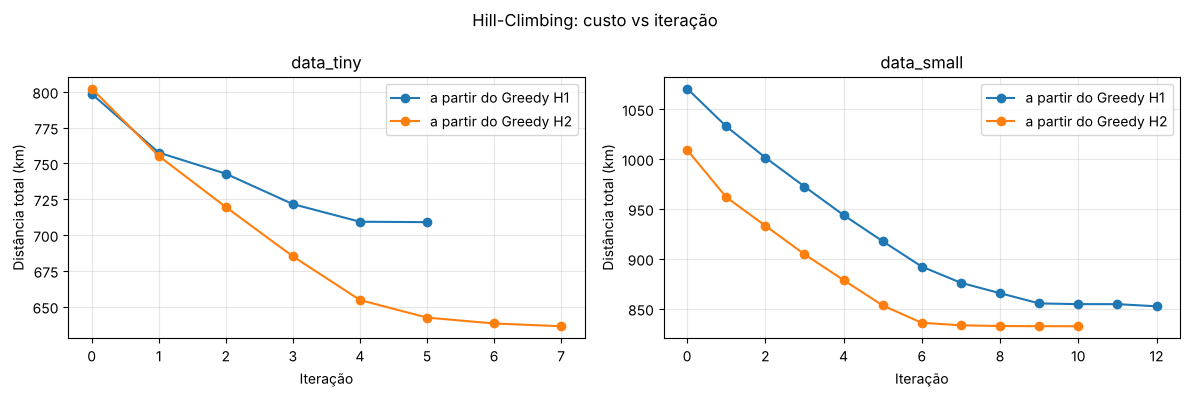

In [5]:
fig, eixos = plt.subplots(1, 2, figsize=(12, 4))
for eixo, nome in zip(eixos, problemas):
    for h_nome in heuristicas:
        historico = resultados[(nome, h_nome)][1]
        eixo.plot(range(len(historico)), historico, marker="o", label=f"a partir do Greedy {h_nome}")
    eixo.set_title(f"{nome}")
    eixo.set_xlabel("Iteração")
    eixo.set_ylabel("Distância total (km)")
    eixo.grid(alpha=0.3)
    eixo.legend()
fig.suptitle("Hill-Climbing: custo vs iteração")
plt.tight_layout()
plt.show()

## 6. Efeito dos tipos de vizinho

Para ver a importância dos três tipos de vizinho, corre-se também o Hill-Climbing **só com o vizinho "trocar"** (a versão mais simples) e compara-se com a versão completa.

In [6]:
gerar_completo = ls.gerar_vizinhos
linhas = []
for (nome, h_nome), inicial in iniciais.items():
    p = problemas[nome]
    ls.gerar_vizinhos = ls.vizinhos_trocar          # só "trocar"
    inicio = time.perf_counter()
    _, hist_trocar, _ = ls.hill_climbing(p, inicial)
    tempo_trocar = time.perf_counter() - inicio
    ls.gerar_vizinhos = gerar_completo              # repor os três tipos
    hist_completo = resultados[(nome, h_nome)][1]
    linhas.append({"Dataset": nome, "Greedy de partida": h_nome, "Greedy (km)": hist_completo[0],
                   "Só trocar (km)": hist_trocar[-1], "Tempo só trocar (s)": round(tempo_trocar, 1),
                   "Três vizinhos (km)": hist_completo[-1]})
pd.DataFrame(linhas)

,Dataset,Greedy de partida,Greedy (km),Só trocar (km),Tempo só trocar (s),Três vizinhos (km)
0,data_tiny,H1,798.54,745.25,0.6,708.96
1,data_tiny,H2,802.24,699.62,1.1,636.31
2,data_small,H1,1070.60,930.68,6.5,852.38
3,data_small,H2,1009.19,857.47,4.3,832.41


## 7. A melhor solução encontrada

Rotas da melhor solução do Hill-Climbing em cada dataset.

In [7]:
for nome in problemas:
    melhor_h = min(heuristicas, key=lambda h: resultados[(nome, h)][1][-1])
    print("=" * 90)
    print(f"{nome} — melhor: Hill-Climbing a partir do Greedy {melhor_h}\n")
    print_solution(problemas[nome], resultados[(nome, melhor_h)][0])
    print()

data_tiny — melhor: Hill-Climbing a partir do Greedy H2

Solução válida | total: 636.31 km

Veículo 1 (capacidade 150 kg)
  30/10 09:00  pickup   Campos Leite                 [12, 23, 27, 28, 30, 33, 36, 38, 39] +37.7 km
  30/10 09:41  pickup   Hortas Valente               [5, 13, 25, 31, 32, 34, 37, 40] +23.6 km
  30/10 10:32  unload   Centro de Recolha 1          [5, 12, 13, 23, 25, 27, 28, 30, 31, 32, 33, 34, 36, 37, 38, 39, 40] +30.6 km
  30/10 10:47  load     Centro de Recolha 1          [36, 37, 38, 39, 40, 25, 26, 27, 28, 29, 30, 31, 5, 6] +0.0 km
  30/10 12:15  deliver  Casa 2                       [36, 37, 38, 39, 40]     +36.1 km
  30/10 13:13  deliver  Casa 4                       [30, 31]                 +36.3 km
  31/10 08:15  pickup   Campos Leite                 [1, 7, 15, 16, 18]       +54.9 km
  31/10 09:00  pickup   Hortas Valente               [2, 10, 19, 20, 21]      +23.6 km
  31/10 09:29  deliver  Loja 5                       [25, 26, 27, 28, 29]     +14.9 km
  31

## 8. Análise dos resultados

**O Hill-Climbing melhora sempre a solução do Greedy.** Em todos os casos a solução final é válida e tem entre **11% e 21% menos km**:

| Dataset | Greedy | Hill-Climbing | Melhoria |
|---|---:|---:|---:|
| tiny (a partir do H1) | 798,54 | 708,96 | 11,2% |
| tiny (a partir do H2) | 802,24 | **636,31** | 20,7% |
| small (a partir do H1) | 1070,60 | 852,38 | 20,4% |
| small (a partir do H2) | 1009,19 | **832,41** | 17,5% |

**As curvas mostram o comportamento típico do Hill-Climbing:** as primeiras iterações dão as maiores descidas e depois as melhorias ficam pequenas (no small, depois da 8.ª iteração ganham-se poucos km por iteração), até a curva ficar plana num **ótimo local**.

**O ponto de partida importa.** No tiny, o Greedy H1 começa melhor (798,54 contra 802,24 km), mas o Hill-Climbing a partir do H2 chega mais longe (636,31 contra 708,96 km). O Hill-Climbing só consegue descer até ao ótimo local mais próximo, e esse depende da solução inicial.

**Mais tipos de vizinho, melhores soluções.** Só com o vizinho "trocar", as soluções finais são piores (por exemplo 699,62 em vez de 636,31 km no tiny, e 857,47 em vez de 832,41 km no small). Os vizinhos "mover" e "passar" dão mais caminhos para descer. Em contrapartida, há muito mais vizinhas para avaliar, e o tempo sobe (no small, de cerca de 5 para cerca de 30–40 segundos).

**A maioria das vizinhas é inválida.** Na primeira iteração do tiny, só 35 de 777 vizinhas são válidas (cerca de 4,5%). Grande parte do tempo é gasta a verificar vizinhas que violam regras (por exemplo, uma entrega antes da carga ou uma janela de tempo ultrapassada).

**Comparação com os outros algoritmos.** O Hill-Climbing dá as melhores soluções válidas do projeto: 636,31 km no tiny e 832,41 km no small, contra 798,54 / 1009,19 km do Greedy e 664,25 / 877,63 km do CSP. Em troca, é o mais lento, porque avalia milhares de vizinhas.

## 9. Conclusão

O Hill-Climbing, aplicado à solução do Greedy, melhora-a de forma consistente (11% a 21% menos km) e mantém sempre todas as restrições, porque cada vizinha é verificada com o `model.py`. As curvas de custo mostram melhorias rápidas no início e a paragem num ótimo local.

**Melhorias futuras:**
- **Simulated annealing:** aceitar, de vez em quando, vizinhas piores para conseguir sair de ótimos locais.
- **Recomeços aleatórios:** correr o Hill-Climbing a partir de várias soluções iniciais e ficar com a melhor.
- **Primeira melhoria em vez da melhor:** aceitar a primeira vizinha melhor que aparece, o que reduz o tempo por iteração.
- **Filtrar vizinhas obviamente inválidas** antes de as simular (por exemplo, entregas antes das cargas), para gastar menos tempo.
